Training features shape: (13903, 11)
Target distribution in test set:
is_peak_demand
0    0.756617
1    0.243383
Name: proportion, dtype: float64

--- Logistic Regression ---
              precision    recall  f1-score   support

           0       0.83      0.93      0.88      2630
           1       0.67      0.41      0.51       846

    accuracy                           0.81      3476
   macro avg       0.75      0.67      0.70      3476
weighted avg       0.79      0.81      0.79      3476

ROC-AUC: 0.8230

--- Random Forest Classifier ---
              precision    recall  f1-score   support

           0       0.95      0.97      0.96      2630
           1       0.90      0.86      0.88       846

    accuracy                           0.94      3476
   macro avg       0.93      0.91      0.92      3476
weighted avg       0.94      0.94      0.94      3476

ROC-AUC: 0.9820


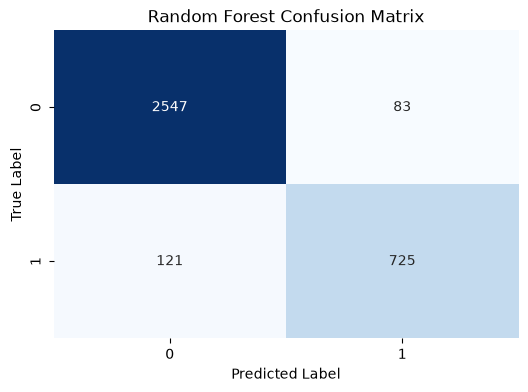

In [1]:
import sys
sys.path.append('../src')
from preprocessing import load_and_preprocess, split_and_scale

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve

# 1. Load Data and use the Classification Target (y_clf)
X, _, y_clf = load_and_preprocess()
X_train, X_test, y_train, y_test = split_and_scale(X, y_clf)

print(f"Training features shape: {X_train.shape}")
print(f"Target distribution in test set:\n{y_test.value_counts(normalize=True)}")

# 2. Train a Baseline Linear Classifier
log_reg = LogisticRegression(random_state=42, max_iter=1000)
log_reg.fit(X_train, y_train)
lr_preds = log_reg.predict(X_test)
lr_probs = log_reg.predict_proba(X_test)[:, 1] # Probabilities for ROC AUC

# 3. Train an Ensemble Classifier
rf_clf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_clf.fit(X_train, y_train)
rf_preds = rf_clf.predict(X_test)
rf_probs = rf_clf.predict_proba(X_test)[:, 1]

# 4. Evaluation 
print("\n--- Logistic Regression ---")
print(classification_report(y_test, lr_preds))
print(f"ROC-AUC: {roc_auc_score(y_test, lr_probs):.4f}")

print("\n--- Random Forest Classifier ---")
print(classification_report(y_test, rf_preds))
print(f"ROC-AUC: {roc_auc_score(y_test, rf_probs):.4f}")

# 5. Visualizing the Confusion Matrix for Random Forest
plt.figure(figsize=(6, 4))
cm = confusion_matrix(y_test, rf_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Random Forest Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.savefig('../figures/rf_confusion_matrix.png') # Saving for MLLB report
plt.show()

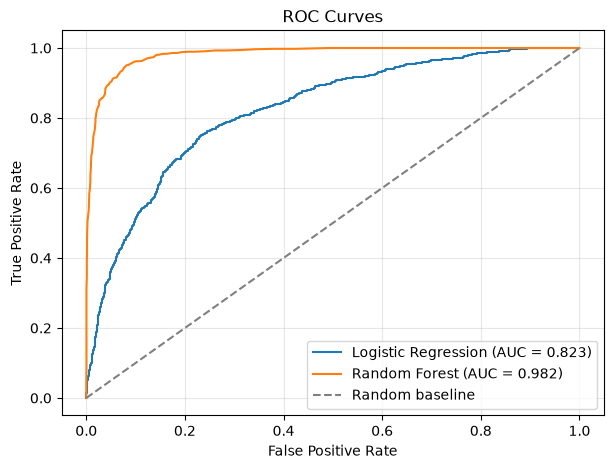

In [2]:
lr_fpr, lr_tpr, _ = roc_curve(y_test, lr_probs)
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_probs)

plt.figure(figsize=(7, 5))
plt.plot(lr_fpr, lr_tpr, label=f'Logistic Regression (AUC = {roc_auc_score(y_test, lr_probs):.3f})')
plt.plot(rf_fpr, rf_tpr, label=f'Random Forest (AUC = {roc_auc_score(y_test, rf_probs):.3f})')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random baseline')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves')
plt.legend()
plt.grid(alpha=0.3)
plt.show()